<a href="https://colab.research.google.com/github/HAX1122/credit-card-fraud-detection/blob/main/Copy_of_hatem_2337073_alwleed_2342305.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, silhouette_score
np.random.seed(42)

In [2]:
from sklearn.datasets import make_classification

X_env, y_env = make_classification(n_samples=300, n_features=6, n_informative=6, n_classes=2,n_redundant=0, random_state=42)
X_env_df = pd.DataFrame(X_env, columns=['Soil_Moisture', 'Temp', 'Light', 'Humidity', 'pH', 'Air_Quality'])
print("Shape:", X_env_df.shape, "| Missing:", X_env_df.isnull().sum().sum())
X_env_df.head()

Shape: (300, 6) | Missing: 0


,Soil_Moisture,Temp,Light,Humidity,pH,Air_Quality
0,-1.534790,-2.310633,-1.198305,-0.913499,-1.289843,-1.261739
1,-0.854594,-0.969256,-1.373560,-0.641997,-0.474611,-0.588785
2,0.666207,-1.351845,-0.866948,1.512356,1.124373,0.788028
3,-0.514175,-1.145269,1.368849,-1.087876,1.021681,2.603809
4,1.701072,-0.744408,0.231406,0.894325,0.818612,-0.239036


In [3]:
X_e_train, X_e_test, y_e_train, y_e_test = train_test_split(X_env_df, y_env, test_size=0.2, random_state=42, stratify=y_env)
scaler_e = StandardScaler()
X_e_train_s = scaler_e.fit_transform(X_e_train)
X_e_test_s = scaler_e.transform(X_e_test)

In [4]:
my_model = LogisticRegression(max_iter=1000, random_state=42)
my_model.fit(X_e_train_s, y_e_train)
my_pred = my_model.predict(X_e_test_s)
my_acc = accuracy_score(y_e_test, my_pred)
my_f1 = f1_score(y_e_test, my_pred, average='macro')
print(f"Tree Health Prediction - Accuracy: {my_acc:.4f}, Macro F1: {my_f1:.4f}")

Tree Health Prediction - Accuracy: 0.9000, Macro F1: 0.9000


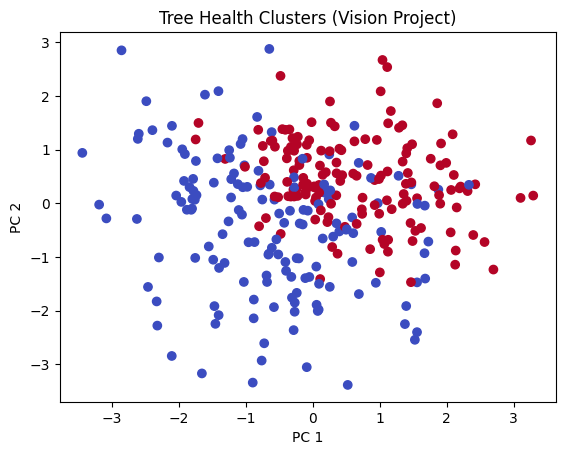

In [5]:
pca_e = PCA(n_components=2)
X_e_pca = pca_e.fit_transform(scaler_e.fit_transform(X_env_df))
plt.scatter(X_e_pca[:, 0], X_e_pca[:, 1], c=y_env, cmap='coolwarm')
plt.title("Tree Health Clusters (Vision Project)")
plt.xlabel("PC 1"); plt.ylabel("PC 2"); plt.show()